# Quantum Metal A.3 — four qubits with multiplexed readout (Quantcore PDK rebuild)

**What the chip is.** The frequency-multiplexed readout example from the Qiskit Metal tutorial
`docs/tut/full-design-examples/A.3-Four-qubit-multiplexed-readout.ipynb` (© IBM / Qiskit Metal contributors,
Apache-2.0, <https://github.com/qiskit-community/qiskit-metal>; spec `docs/designs/metal/A3_four_qubit_mux.md`):
four uncoupled `TransmonPocket`s (pad width 425 µm, pocket height 650 µm, one readout pad at the upper right) in a
row at x = −4.5, −1.5, 1.5, 4.5 mm; each has a λ/4 `RouteMeander` readout (6.8, 7.0, 7.2, 7.4 mm) from a
`CoupledLineTee` on one feedline between two `LaunchpadWirebond`s, so the four readouts sit at four distinct tones
on one line. We distribute the rebuild under GPL-3.0.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options, but the chip, the
stack, the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal tutorial | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 16 × 9 mm centred on (0, 0) | the same 16 × 9 mm box (it does not fit the 7.5 mm die), shifted by (+8, +4.5) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | `LaunchpadWirebond` at x = ±7.5 mm (outer edge 240 µm in) | the same pads, moved to **100 µm** (`frame.pad_edge`) from the west / east edges (PDK pad rule) |
| junctions | Metal junction line, `hfss_inductance` 10 nH | Quantcore Nb/AlOx/Nb trilayer junctions, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) on all four qubits |
| cheese | none (the tutorial never exports GDS) | the PDK band (chip `cheese: "auto"`) |
| routes | `RoutePathfinder` feedline segments, `RouteMeander` readouts | qcc `cpw` routes on the same pins; qcc meanders of the same lengths (6800 … 7400 µm; turn radius 90 µm = Metal's fillet) |
| placement | as drawn | content centred in the die |

**Kept exactly:** every component with the tutorial's options (tees: `coupling_length` 350 µm, `down_length`
300 µm, `fillet` 90 µm, `open_termination=False`), their relative positions, the five feedline segments, every
route's end pins and the readout total lengths, the four sim groups.

**Simplified:** the qcc router places each readout meander itself (Metal: 100 µm lead straights): same end points
and lengths, different meander footprints.

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 16 × 9 mm box gets the QCT frame; the two launchpads go 100 µm from the west and east edges; all four qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (it is optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position is shifted by `(X0, Y0)` = half the chip.

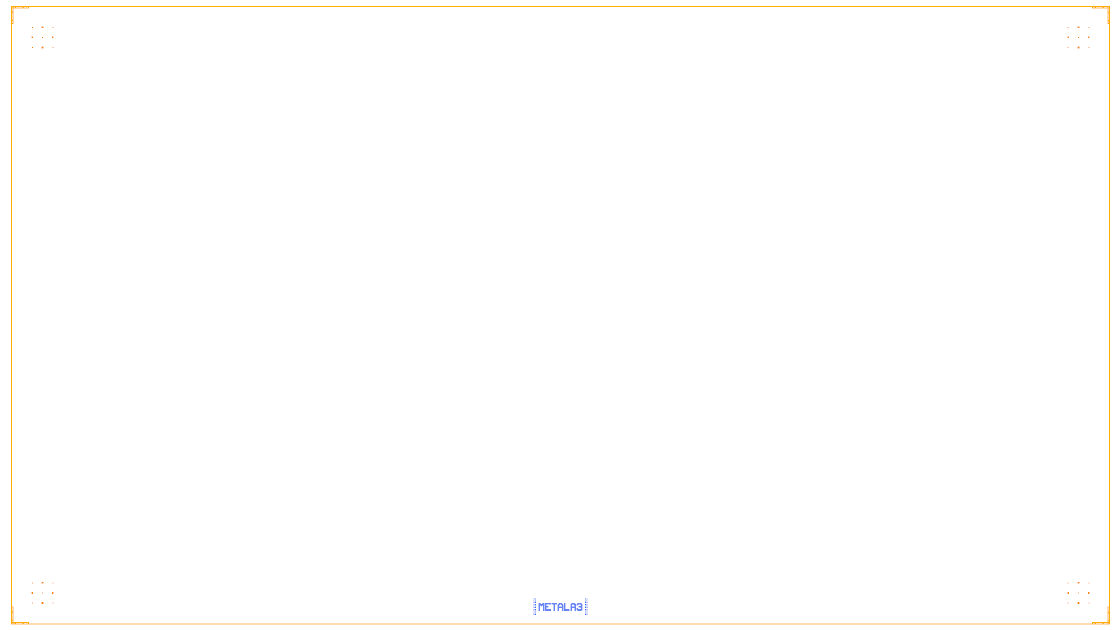

WindowsPath('examples/designs/metal/a3_four_qubit_mux_step_die.png')

In [4]:
d = Designer("a3_four_qubit_mux", box=(0, 0, 16000, 9000), chip={"name_chip": "MetalA3"}, live=LIVE)
X0, Y0 = 8000, 4500                              # Metal's 16 × 9 mm chip is centred on (0, 0)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "a3_four_qubit_mux_step_die.png", size=(1120, 630), width=450)

## 4 · Pads: the PDK pad rule

The tutorial puts its input and output `LaunchpadWirebond`s at x = ±7.5 mm on the feedline height, 240 µm in from
the die edge. In the Quantcore PDK the outer edge of every bond pad's etch sits **one dicing-marker width (25 µm)
from the die edge**, whatever the source did: `edge="w"` / `"e"` slides the pad perpendicular to that edge until it
is there; its position along the edge (the feedline height) is kept. The table measures it on the built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| LPin | `metal:LaunchpadWirebond` | w | 100.0 | ✓ |
| LPout | `metal:LaunchpadWirebond` | e | 100.0 | ✓ |

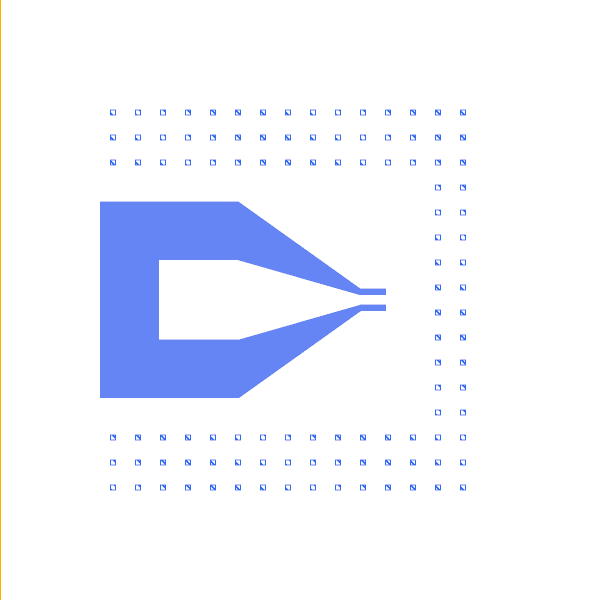

WindowsPath('examples/designs/metal/a3_four_qubit_mux_step_pads.png')

In [5]:
with d.batch():
    d.add("LPin", "metal:LaunchpadWirebond", at=(X0 - 7500, Y0 + 1800), rot=0, edge="w")
    d.add("LPout", "metal:LaunchpadWirebond", at=(X0 + 7500, Y0 + 1800), rot=180, edge="e")
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "LPin.tie")
snap(d, OUT / "a3_four_qubit_mux_step_pads.png", box=(0, py - 300, 600, py + 300), size=(600, 600), width=300)

## 5 · Components: four qubits and four tees

**The qubits.** Four `metal:TransmonPocket`s with the tutorial's options: two 425 µm pads in a 650 µm-high pocket
and one `readout` connection pad at the upper right. Their junctions are the PDK's: `trilayer_junction` makes the
Quantcore trilayer junction explicit and returns its L_J and C_J for the LOM and the FEM junction port
(`junction=`). The tutorial gives no target frequencies, so all four get the PDK nominal junction (fingers
0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF): the
four qubits stay identical, and only the readouts differ.

**The tees.** Four `metal:CoupledLineTee`s on the feedline, above their qubits, each with a 350 µm coupled arm;
`open_termination=False` shorts the arm's far end, so each readout routed from `second_end` is a λ/4.

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['readout', 'squid_a', 'squid_b'] | clt1 ports: ['prime_end', 'prime_start', 'second_end']


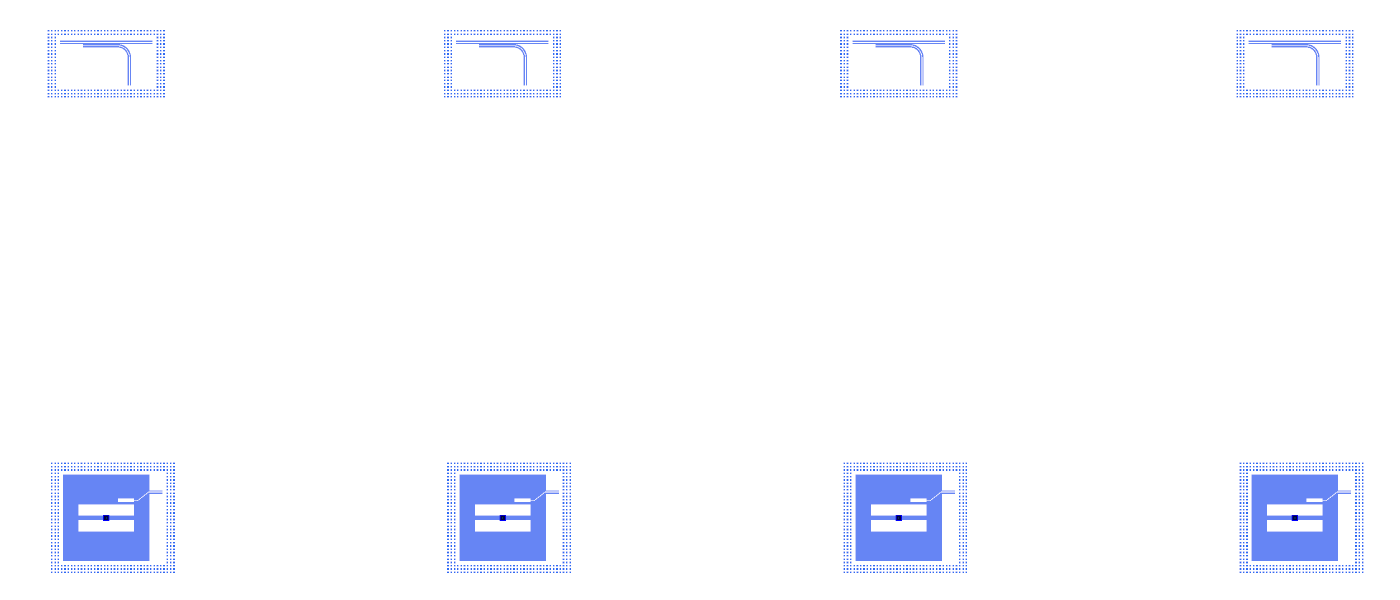

WindowsPath('examples/designs/metal/a3_four_qubit_mux_step_parts.png')

In [6]:
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
XS = [-4500, -1500, 1500, 4500]                  # Metal x of the four qubits (µm)
with d.batch():
    for i, x in enumerate(XS, start=1):
        d.add(f"Q{i}", "metal:TransmonPocket", at=(X0 + x, Y0 - 1800), pad_width=425, pocket_height=650,
              connection_pads={"readout": {"loc_W": 1, "loc_H": 1}}, junction=JUNCTION, **JJ_PARAMS)
        d.add(f"clt{i}", "metal:CoupledLineTee", at=(X0 + x, Y0 + 1800), coupling_length=350, down_length=300,
              fillet=90, open_termination=False)
print("Q1 ports:", sorted(d["Q1"].ports), "| clt1 ports:", sorted(d["clt1"].ports))
snap(d, OUT / "a3_four_qubit_mux_step_parts.png", box=(X0 - 5300, Y0 - 2400, X0 + 5300, Y0 + 2100), size=(1400, 600),
     width=560)

## 6 · Routes: feedline and four readouts

- **Feedline:** five `cpw` routes, input pad → four tees → output pad, on the PDK's default CPW (10 µm centre, 6 µm
  gap) with the tutorial's 90 µm fillet as the turn radius.
- **Readouts:** fixed-length meanders (6.8, 7.0, 7.2, 7.4 mm) from each tee's coupled arm to its qubit's readout
  pad; the 200 µm steps give four tones ≈ 100 MHz apart near 4 GHz (λ/4 on sapphire): one line reads all four.
- **Sim groups:** each qubit with its readout and tee (C-matrix + eigenmode).

route lengths (µm): {'f0': 2765.0, 'f1': 2300.0, 'f2': 2300.0, 'f3': 2300.0, 'f4': 2765.0, 'read1': 6800.0, 'read2': 7000.0, 'read3': 7200.0, 'read4': 7400.0}


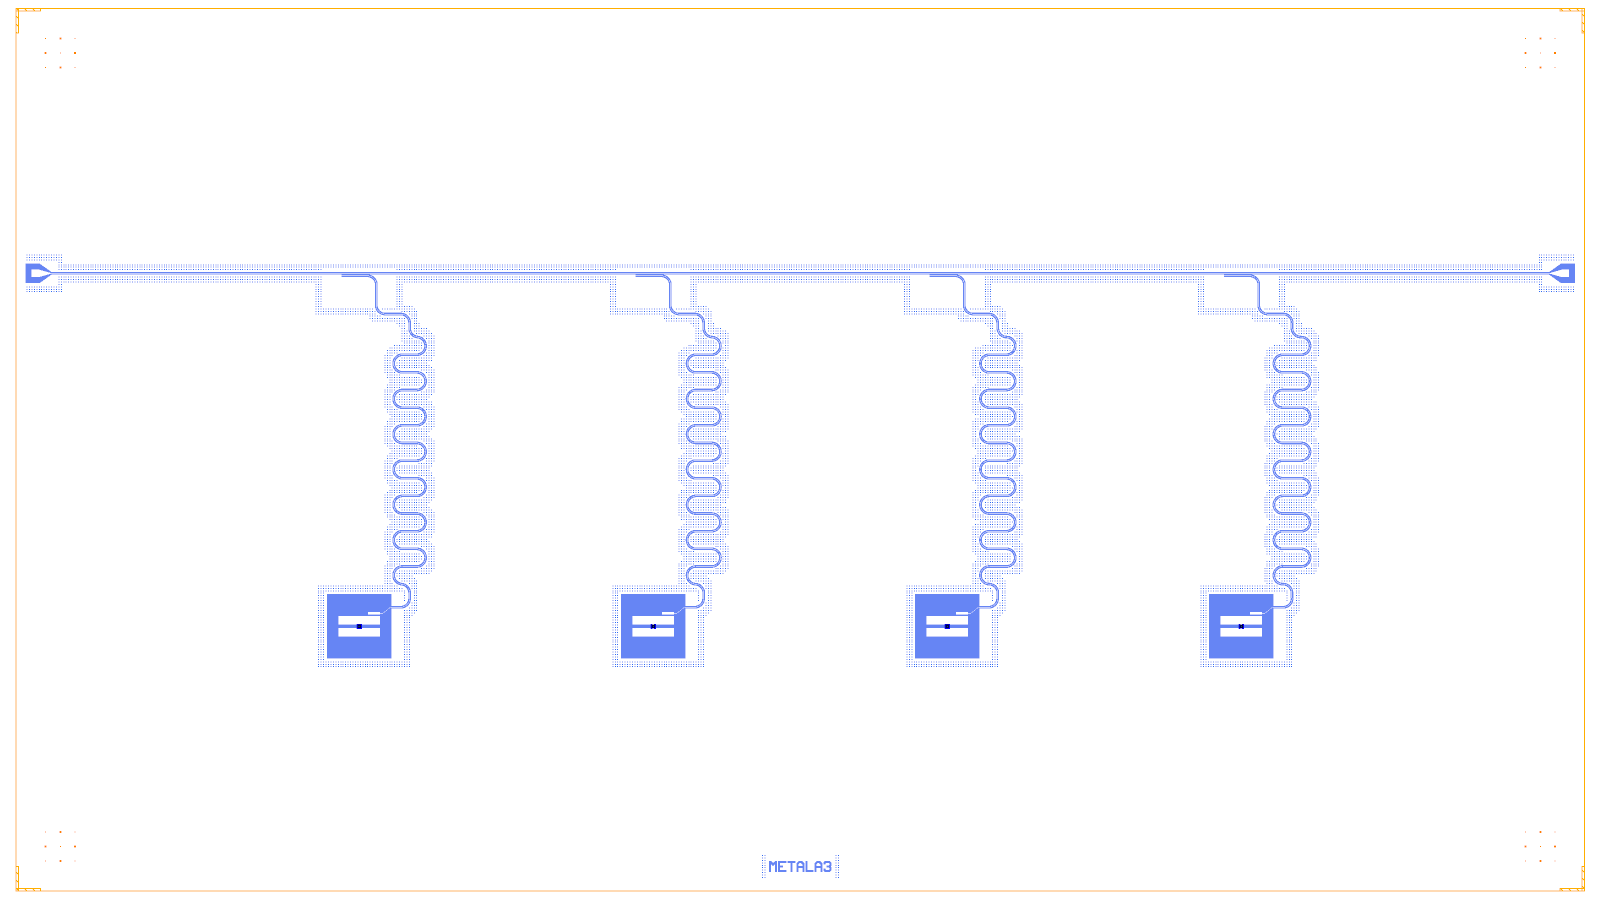

WindowsPath('examples/designs/metal/a3_four_qubit_mux_step_routes.png')

In [7]:
lengths = [6800, 7000, 7200, 7400]
with d.batch():
    d.route("f0", "LPin.tie", "clt1.prime_start", r=90)
    for i in range(1, 4):
        d.route(f"f{i}", f"clt{i}.prime_end", f"clt{i + 1}.prime_start", r=90)
    d.route("f4", "clt4.prime_end", "LPout.tie", r=90)
    for i, length in enumerate(lengths, start=1):
        d.route(f"read{i}", f"clt{i}.second_end", f"Q{i}.readout", meander=length, r=90)
for i in range(1, 5):
    d.sim_group(f"Q{i}_read{i}", [f"Q{i}", f"read{i}", f"clt{i}"], analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "a3_four_qubit_mux_step_routes.png", size=(1600, 900), width=560)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). The pads span the die in x, so only y moves (the source's qubits hang below the
feedline). Then the design is saved: the JSON is the deliverable.

In [8]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "a3_four_qubit_mux.json")
print(d, "→", DESIGN)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})

content shifted by (0.0, 113.5) µm
<Designer a3_four_qubit_mux: 10 instances, 9 routes, live=False> → examples\designs\metal\a3_four_qubit_mux.json
route lengths (µm): {'f0': 2765.0, 'f1': 2300.0, 'f2': 2300.0, 'f3': 2300.0, 'f4': 2765.0, 'read1': 6800.0, 'read2': 7000.0, 'read3': 7200.0, 'read4': 7400.0}


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, eight `dangling_port` warnings (`squid_a` / `squid_b` of the four qubits, the
junction attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junctions are in the R_n window, no target is outside 4–8 GHz).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [9]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 8 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocket` is two floating pad nodes with the junction
between them plus a readout-pad node; each readout meander from its shorted tee to the readout pad is a λ/4
`TLres`, the tee's coupled section a hanger κ into the feedline node (two 50 Ω launchpads). The four hangers share
one feedline node: that is the multiplexing. The port map shows which node each port landed on.

In [10]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "clt1."))})

**14 nodes · 38 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `clt1.prime` | `LPin.pad`, `LPout.pad`, `clt1.prime`, `clt2.prime`, `clt3.prime`, `clt4.prime` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.readout` | `Q1.readout`, `clt1.second_end` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.readout` | `Q2.readout`, `clt2.second_end` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.readout` | `Q3.readout`, `clt3.second_end` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |
| `Q4.readout` | `Q4.readout`, `clt4.second_end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_LPin` | R | `clt1.prime` – `gnd` | 50 Ω |
| `Port_LPout` | R | `clt1.prime` – `gnd` | 50 Ω |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 34.3 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 34.3 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 26.2 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_readout` | C | `Q1.island1` – `Q1.readout` | 17 fF |
| `Cf_Q1_readout` | C | `Q1.island2` – `Q1.readout` | 1.8 fF |
| `Cc_Q1_readout` | C | `Q1.readout` – `gnd` | 34.3 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 34.3 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 34.3 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 26.2 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_readout` | C | `Q2.island1` – `Q2.readout` | 17 fF |
| `Cf_Q2_readout` | C | `Q2.island2` – `Q2.readout` | 1.8 fF |
| `Cc_Q2_readout` | C | `Q2.readout` – `gnd` | 34.3 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 34.3 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 34.3 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 26.2 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_readout` | C | `Q3.island1` – `Q3.readout` | 17 fF |
| `Cf_Q3_readout` | C | `Q3.island2` – `Q3.readout` | 1.8 fF |
| `Cc_Q3_readout` | C | `Q3.readout` – `gnd` | 34.3 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 34.3 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 34.3 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 26.2 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_readout` | C | `Q4.island1` – `Q4.readout` | 17 fF |
| `Cf_Q4_readout` | C | `Q4.island2` – `Q4.readout` | 1.8 fF |
| `Cc_Q4_readout` | C | `Q4.readout` – `gnd` | 34.3 fF |
| `clt1` | TLres | `Q1.readout` – `gnd` | lambda/4, 7450 µm, 4.229 GHz |
| `K_clt1` | HANGER | `Q1.readout` – `clt1.prime` | κ 0.117 MHz (L 350 µm) |
| `clt2` | TLres | `Q2.readout` – `gnd` | lambda/4, 7650 µm, 4.119 GHz |
| `K_clt2` | HANGER | `Q2.readout` – `clt1.prime` | κ 0.108 MHz (L 350 µm) |
| `clt3` | TLres | `Q3.readout` – `gnd` | lambda/4, 7850 µm, 4.014 GHz |
| `K_clt3` | HANGER | `Q3.readout` – `clt1.prime` | κ 0.1 MHz (L 350 µm) |
| `clt4` | TLres | `Q4.readout` – `gnd` | lambda/4, 8050 µm, 3.914 GHz |
| `K_clt4` | HANGER | `Q4.readout` – `clt1.prime` | κ 0.0929 MHz (L 350 µm) |

**Unconnected ports:** none

**Builder notes:**

- clt1: coupled-line κ uses the hanger k for a 3 µm gap (rough)
- clt2: coupled-line κ uses the hanger k for a 3 µm gap (rough)
- clt3: coupled-line κ uses the hanger k for a 3 µm gap (rough)
- clt4: coupled-line κ uses the hanger k for a 3 µm gap (rough)

{'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.readout': 'Q1.readout', 'clt1.prime_start': 'clt1.prime', 'clt1.prime_end': 'clt1.prime', 'clt1.second_end': 'Q1.readout'}


## 10 · LOM simulation

Each qubit with its readout and the whole feedline (all four tees, five segments, both launchpads): QuTiP dressed
f_q, α, f_r, κ and χ. With the PDK junction (6.73 nH, 15 fF) the four identical qubits sit near 7.4 GHz, above the
3.74–4.03 GHz readouts, which step down by ≈ 100 MHz as the meanders grow; the tutorial states no targets.

In [11]:
feed = ["LPin", "LPout"] + [f"f{i}" for i in range(5)] + [f"clt{i}" for i in range(1, 5)]
results = simulate_groups(d, {f"Q{i}+read{i}": [f"Q{i}", f"read{i}"] + feed for i in range(1, 5)})
display(Markdown(groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+read1 | Q1 | 7.4451 | -345 | clt1 | 4.0311 | 0.0967 | -0.237 |
| Q2+read2 | Q2 | 7.4449 | -345 | clt2 | 3.9305 | 0.0898 | -0.205 |
| Q3+read3 | Q3 | 7.4447 | -345 | clt3 | 3.8348 | 0.0835 | -0.179 |
| Q4+read4 | Q4 | 7.4445 | -345 | clt4 | 3.7436 | 0.0777 | -0.157 |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Per qubit with its readout and tee: a Q3D **C-matrix** job (island pads, readout pad and tee arm) and an
**eigenmode / EPR** job (the lines leaving the box end in 50 Ω, so the mode Q gives κ, and EPR gives the junction
participation): eight jobs.

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [12]:
jobs = export_sims(DESIGN)
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| Q1_read1 | `build/jobs/a3_four_qubit_mux_Q1_read1_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `clt1.second_end`<br>3 · waveguide · `Q1.readout`<br>4 · edge · `f0`<br>5 · edge · `f1` | `Q1.island2`, `Q1.readout`, `f0`, `Q1.island1` |
| Q2_read2 | `build/jobs/a3_four_qubit_mux_Q2_read2_q3d_cmatrix` | 1 · junction · `Q2.junction`<br>2 · waveguide · `clt2.second_end`<br>3 · waveguide · `Q2.readout`<br>4 · edge · `f1`<br>5 · edge · `f2` | `Q2.island2`, `Q2.readout`, `f1`, `Q2.island1` |
| Q3_read3 | `build/jobs/a3_four_qubit_mux_Q3_read3_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `clt3.second_end`<br>3 · waveguide · `Q3.readout`<br>4 · edge · `f2`<br>5 · edge · `f3` | `Q3.island2`, `Q3.readout`, `f2`, `Q3.island1` |
| Q4_read4 | `build/jobs/a3_four_qubit_mux_Q4_read4_q3d_cmatrix` | 1 · junction · `Q4.junction`<br>2 · waveguide · `clt4.second_end`<br>3 · waveguide · `Q4.readout`<br>4 · edge · `f3`<br>5 · edge · `f4` | `Q4.island2`, `Q4.readout`, `f3`, `Q4.island1` |
| Q1_read1 | `build/jobs/a3_four_qubit_mux_Q1_read1_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `f0`<br>3 · edge_lumped · `f1` | `Q1.island2`, `f0`, `f1`, `Q1.island1` |
| Q2_read2 | `build/jobs/a3_four_qubit_mux_Q2_read2_eigenmode_epr` | 1 · junction · `Q2.junction`<br>2 · edge_lumped · `f1`<br>3 · edge_lumped · `f2` | `Q2.island2`, `f1`, `f2`, `Q2.island1` |
| Q3_read3 | `build/jobs/a3_four_qubit_mux_Q3_read3_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `f2`<br>3 · edge_lumped · `f3` | `Q3.island2`, `f2`, `f3`, `Q3.island1` |
| Q4_read4 | `build/jobs/a3_four_qubit_mux_Q4_read4_eigenmode_epr` | 1 · junction · `Q4.junction`<br>2 · edge_lumped · `f3`<br>3 · edge_lumped · `f4` | `Q4.island2`, `f3`, `f4`, `Q4.island1` |

In [13]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['Q1_read1', 'Q2_read2', 'Q3_read3', 'Q4_read4'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [14]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for Q1_read1 · q3d, Q2_read2 · q3d, Q3_read3 · q3d, Q4_read4 · q3d, Q1_read1 · eigenmode, Q2_read2 · eigenmode, Q3_read3 · eigenmode, Q4_read4 · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here clt1's coupled length, 350 → 250 µm — rebuild, re-run the LOM of `Q1+read1` and
compare. The coupled length sets how strongly the λ/4 leaks into the feedline: κ falls roughly with its square, the
readout frequency moves a little (the shorter tee arm shortens the λ/4), the qubit barely moves.

In [15]:
d2 = design_copy(DESIGN)
d2["clt1"].set(coupling_length=250)              # 350 → 250 µm
group = {"Q1+read1": ["Q1", "read1"] + feed}
display(Markdown(params_delta_md({"Q1+read1": results["Q1+read1"]}, simulate_groups(d2, group))))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+read1: clt1.f_GHz` | 4.0311 | 4.0881 | +0.057 |
| `Q1+read1: clt1.kappa_MHz` | 0.096698 | 0.05153 | -0.04517 |
| `Q1+read1: clt1.chi_MHz` | -0.23706 | -0.25738 | -0.02032 |
| `Q1+read1: Q1.f_q_GHz` | 7.4451 | 7.4452 | +0.0001351 |
| `Q1+read1: Q1.alpha_MHz` | -344.96 | -344.94 | +0.01661 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** The A.3 tutorial never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). The build draws it into KQC's `ground_grid` layer (5 µm squares, 20 µm gaps, three
rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [16]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\a3_four_qubit_mux.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 10657 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 10647 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 10645 holes on the mask.

→ `build/a3_four_qubit_mux_fab.oas`

## 15 · Snapshots

The full chip; Q1; its trilayer junction; the clt1 coupled-line tee; the **fab mask** round Q1 (1/0 etch with the
PDK cheese band, the 3/0 keep-out, the junction layers); and the die frame's south-west corner (dicing L on 1000/0,
alignment grid on 1001/0). Positions are read from the design (after the centring shift).

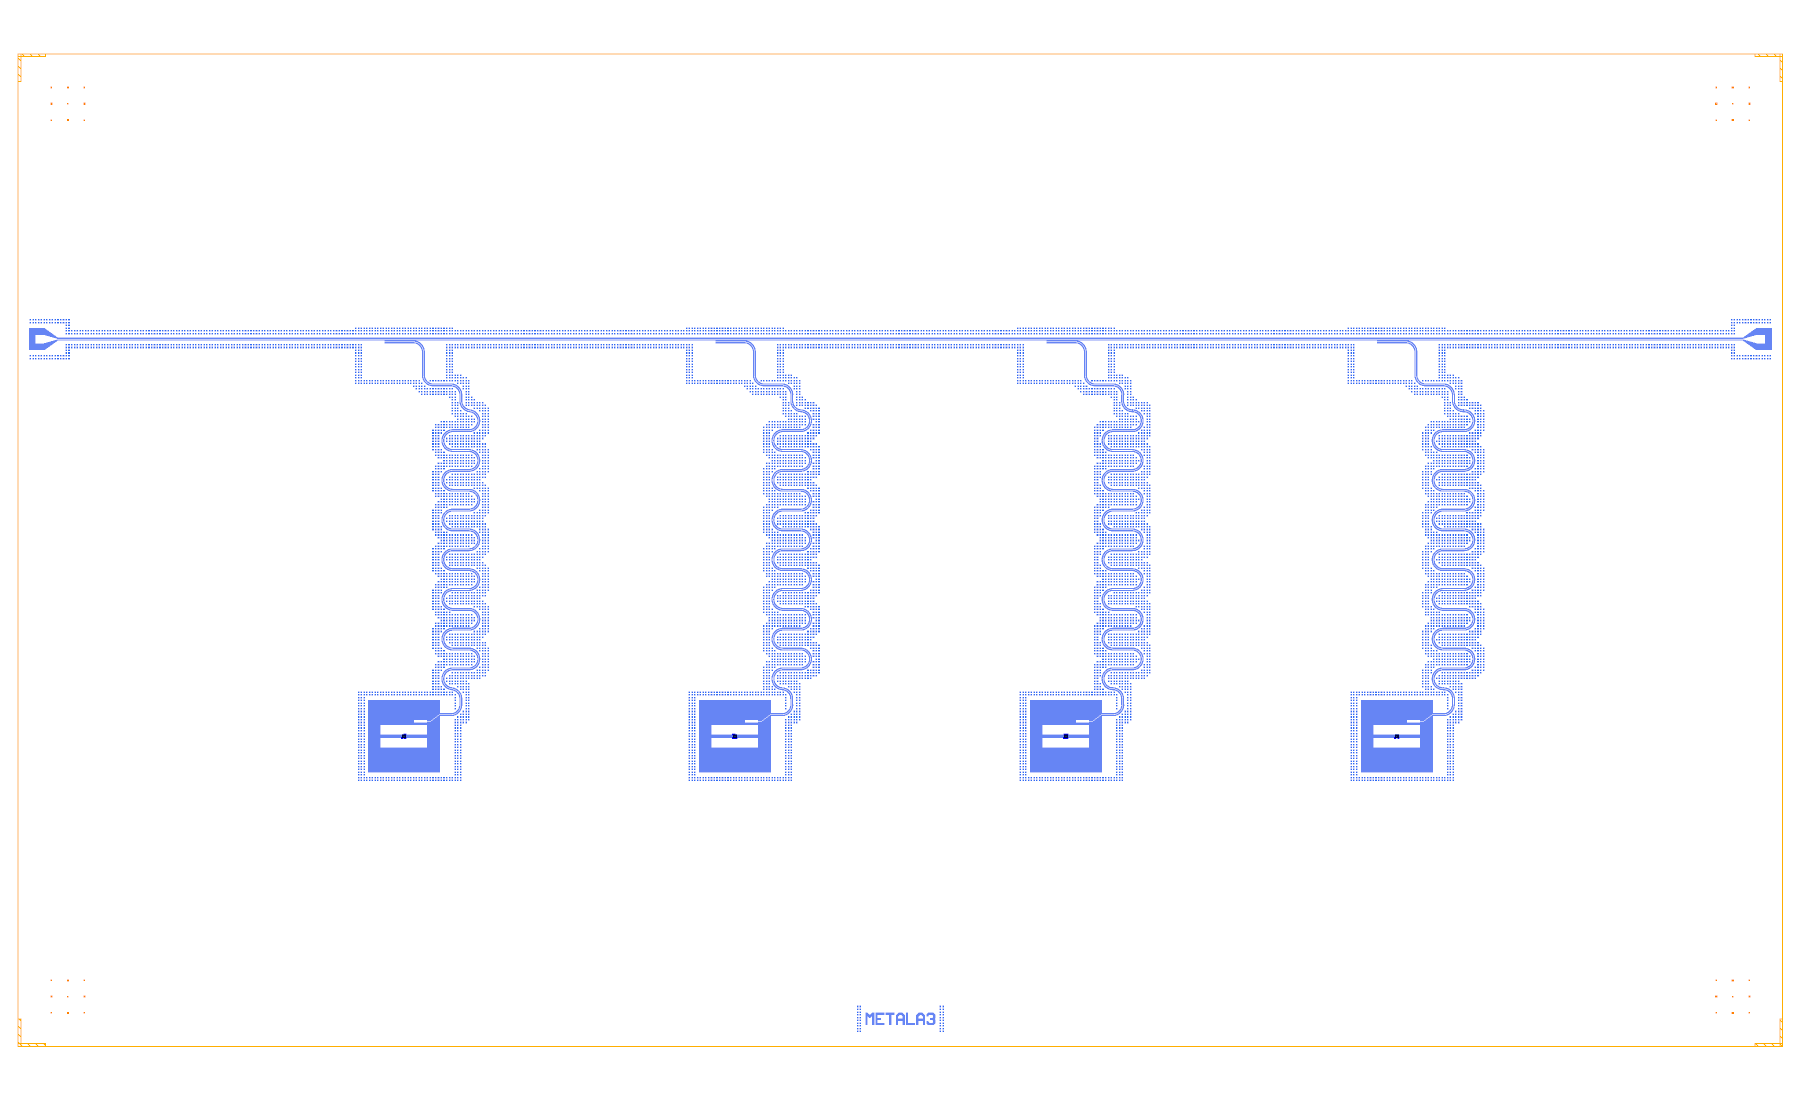

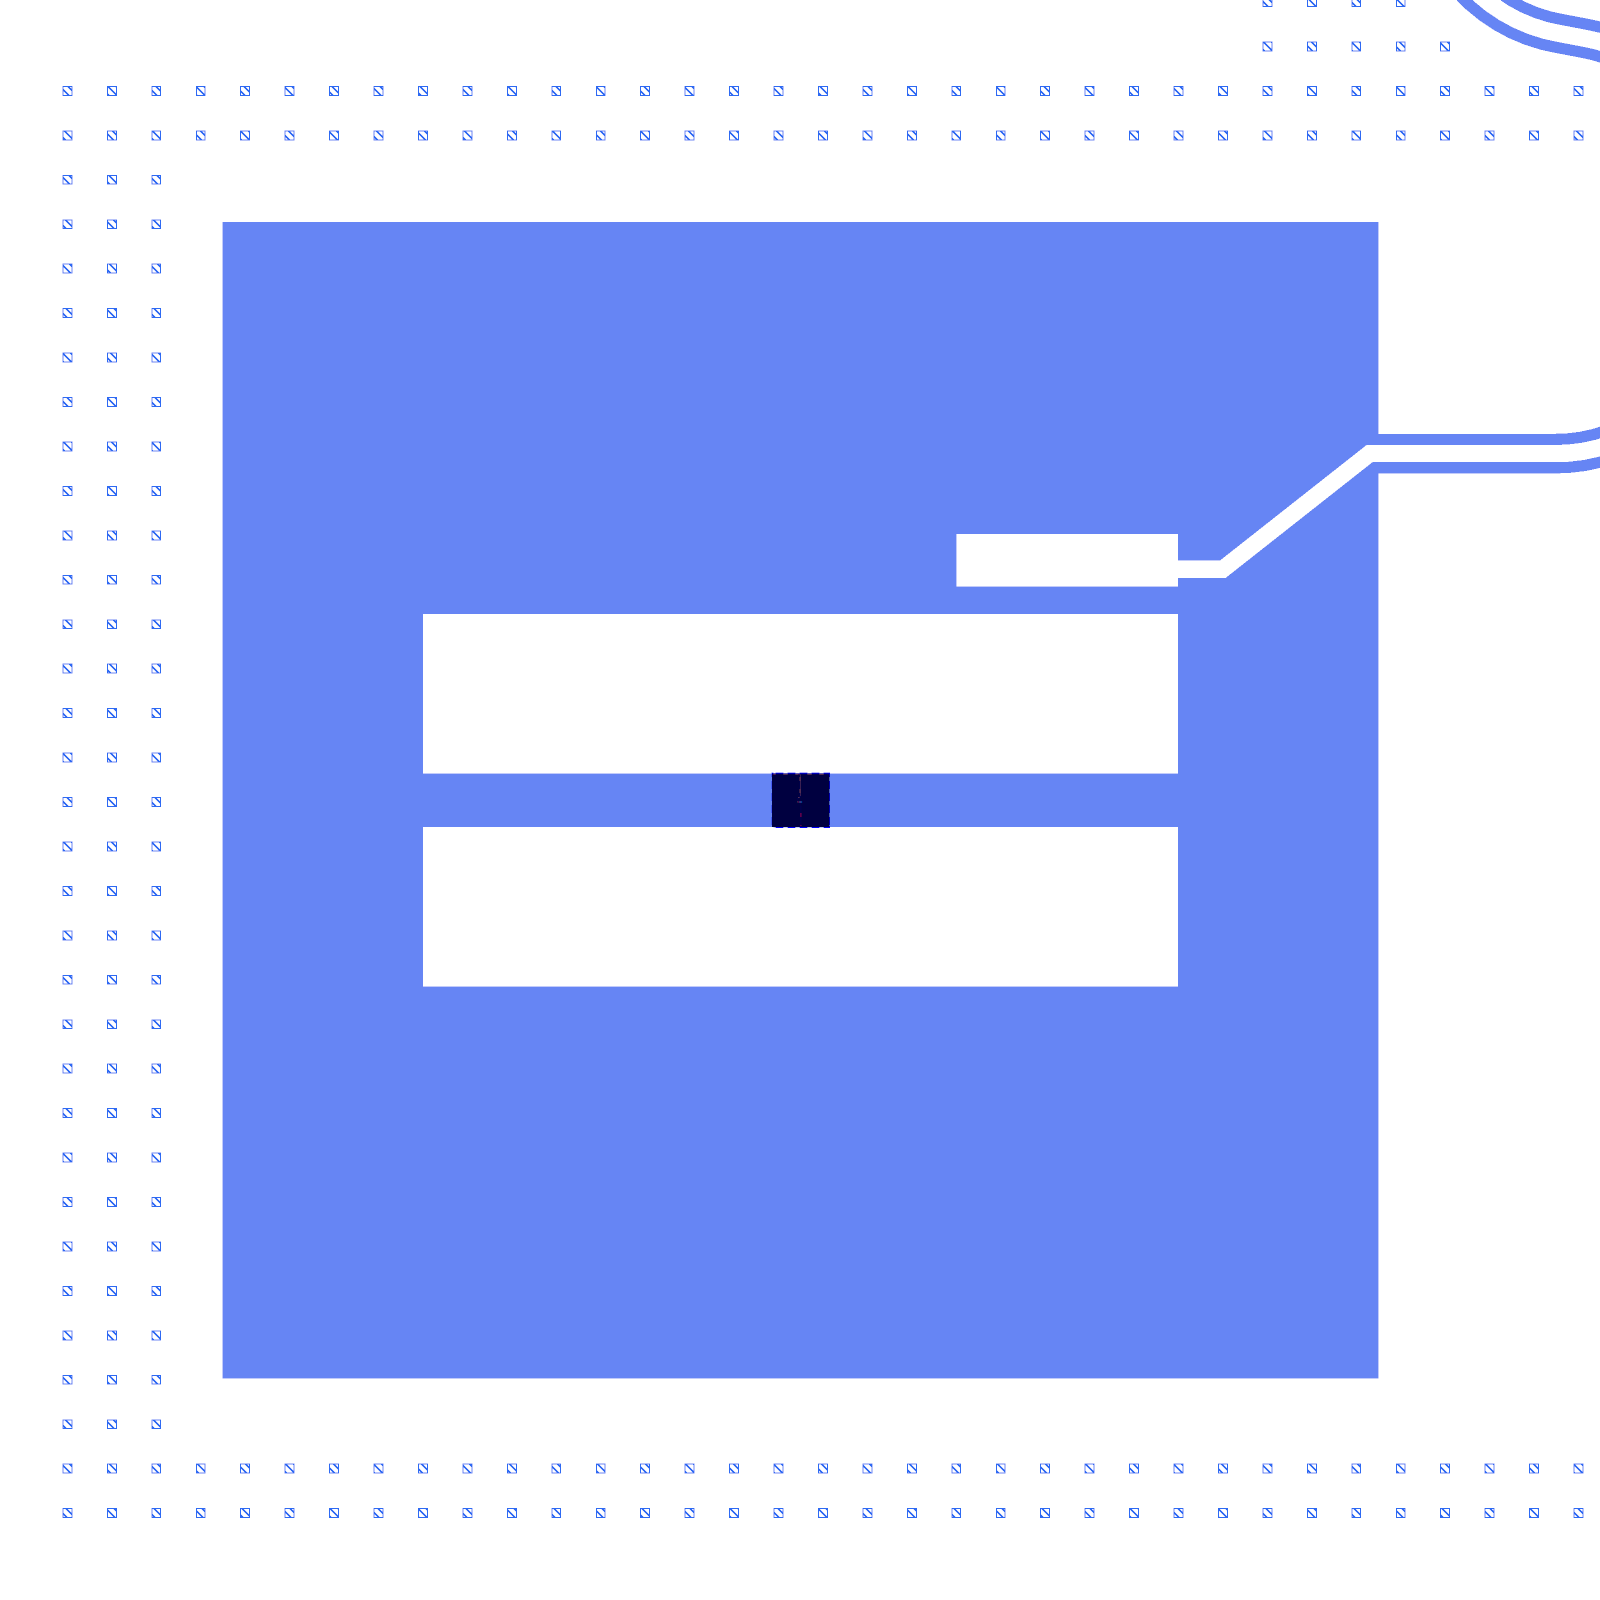

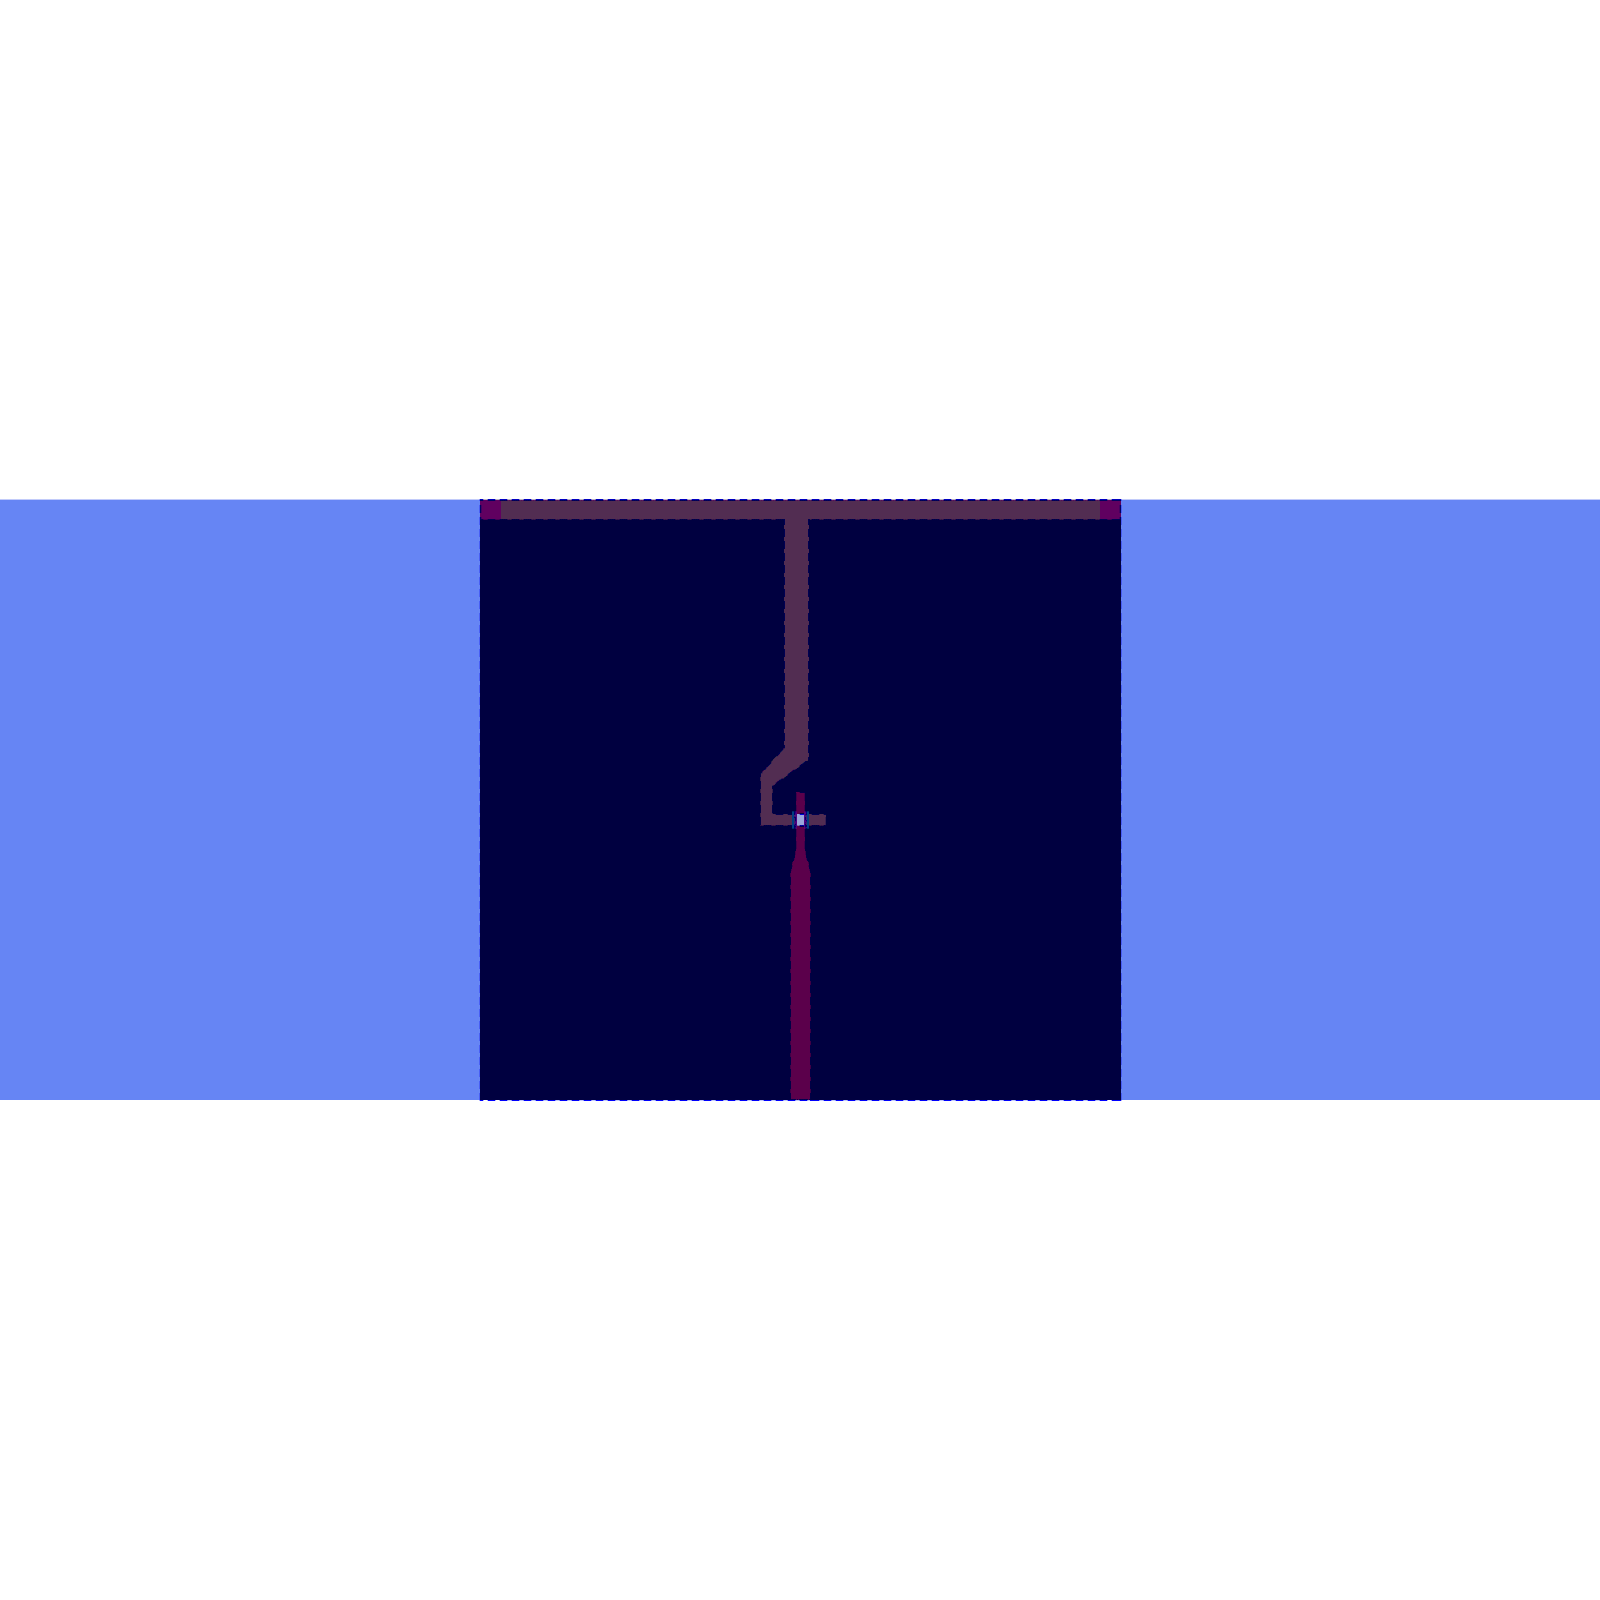

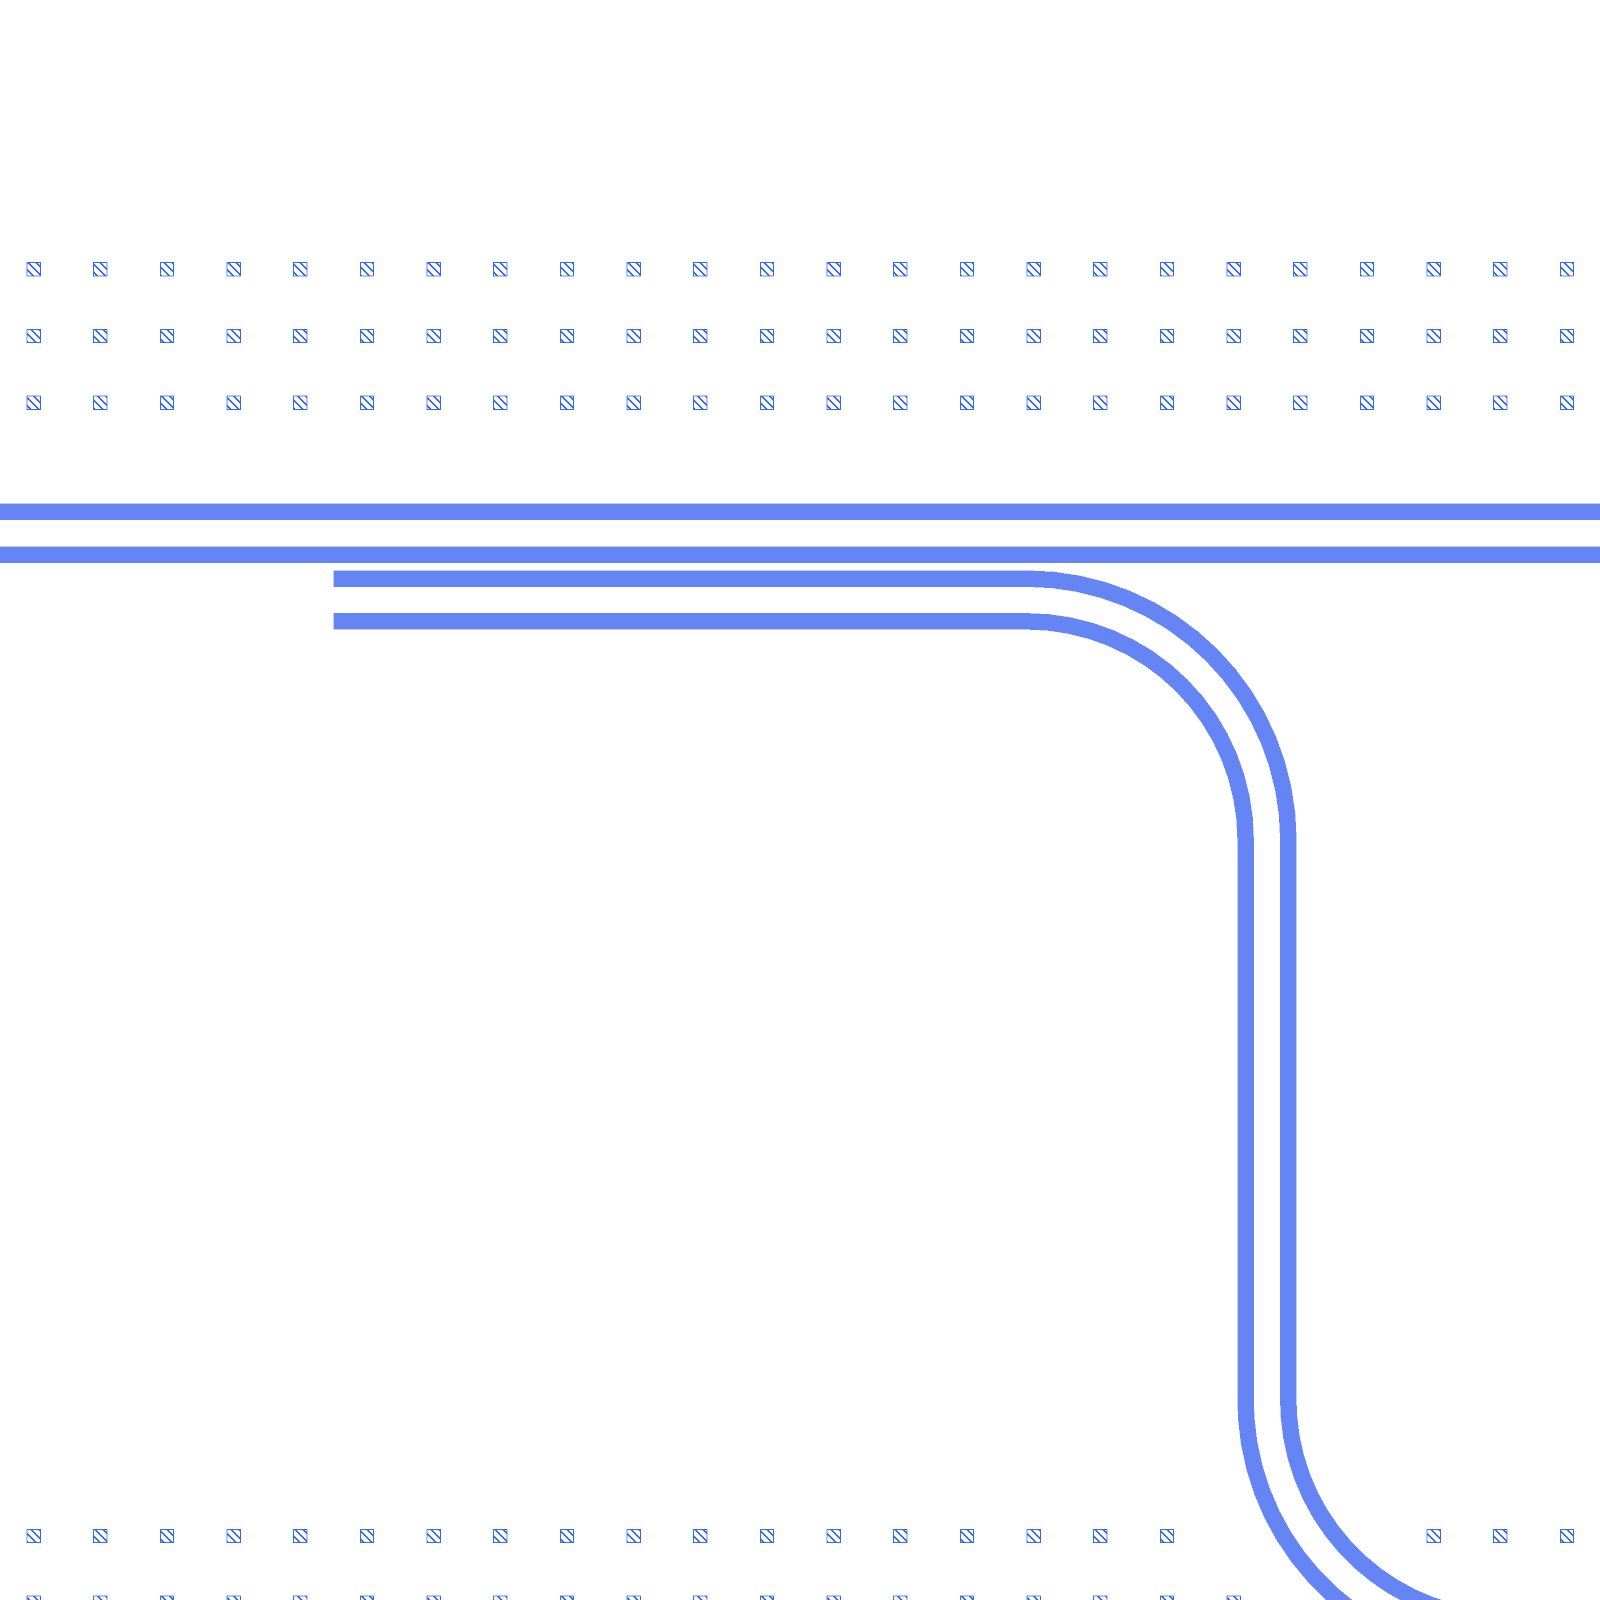

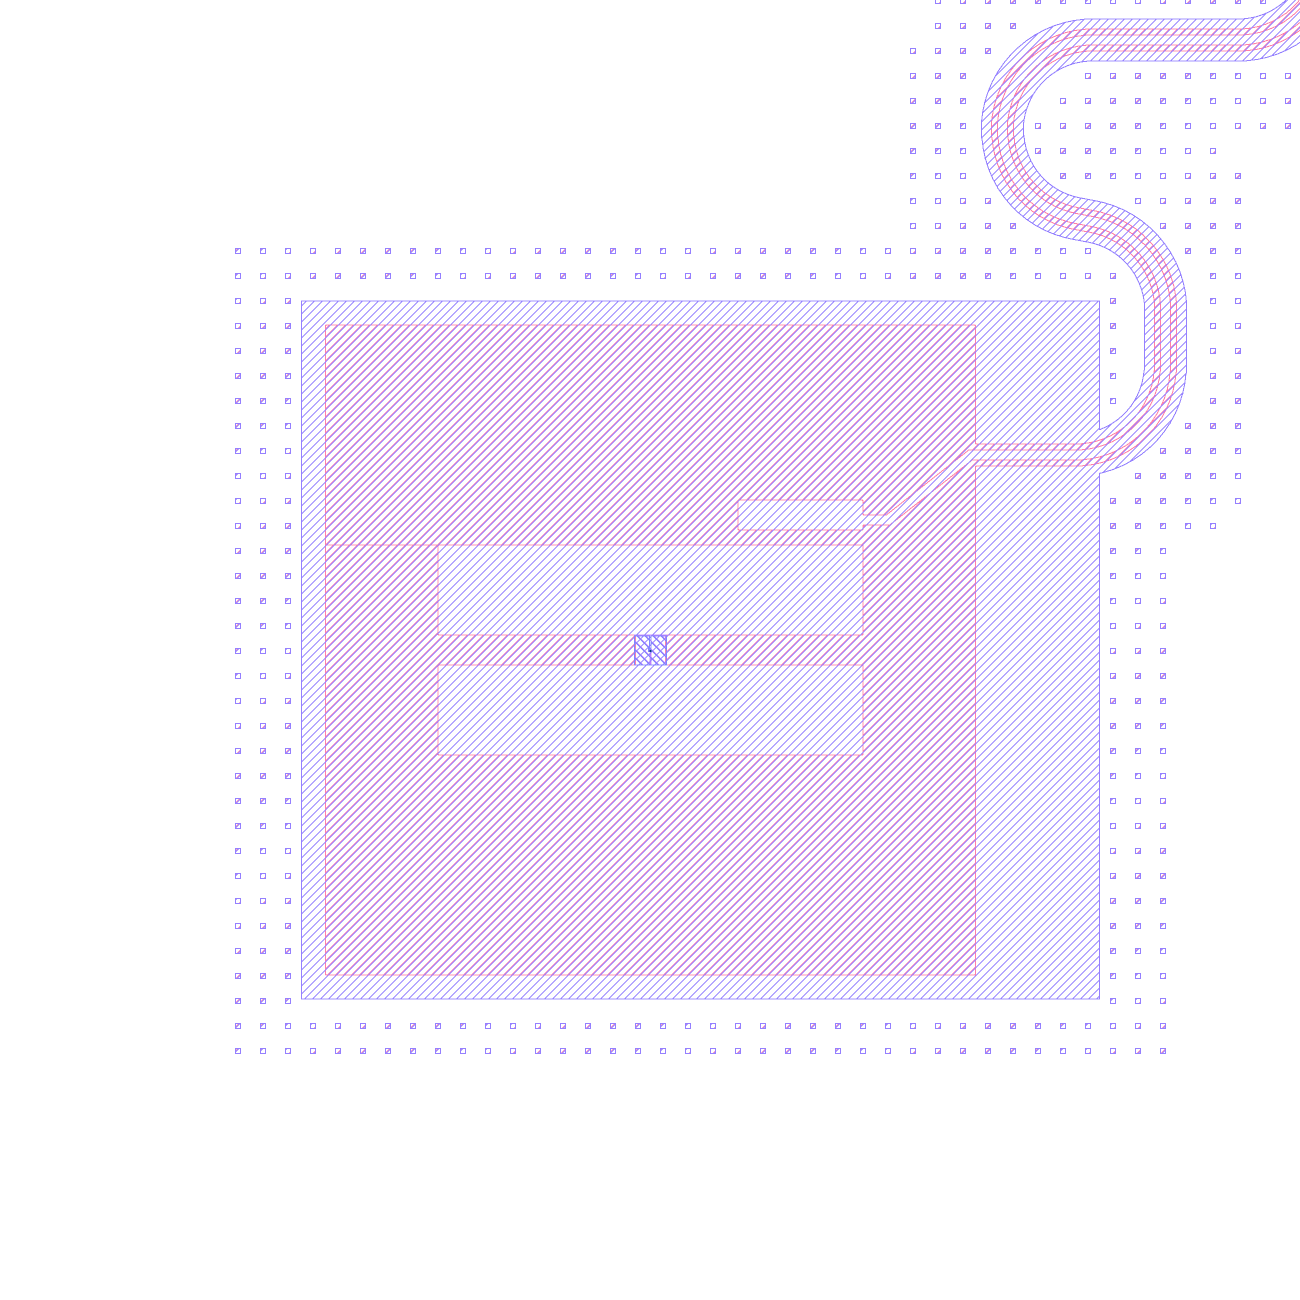

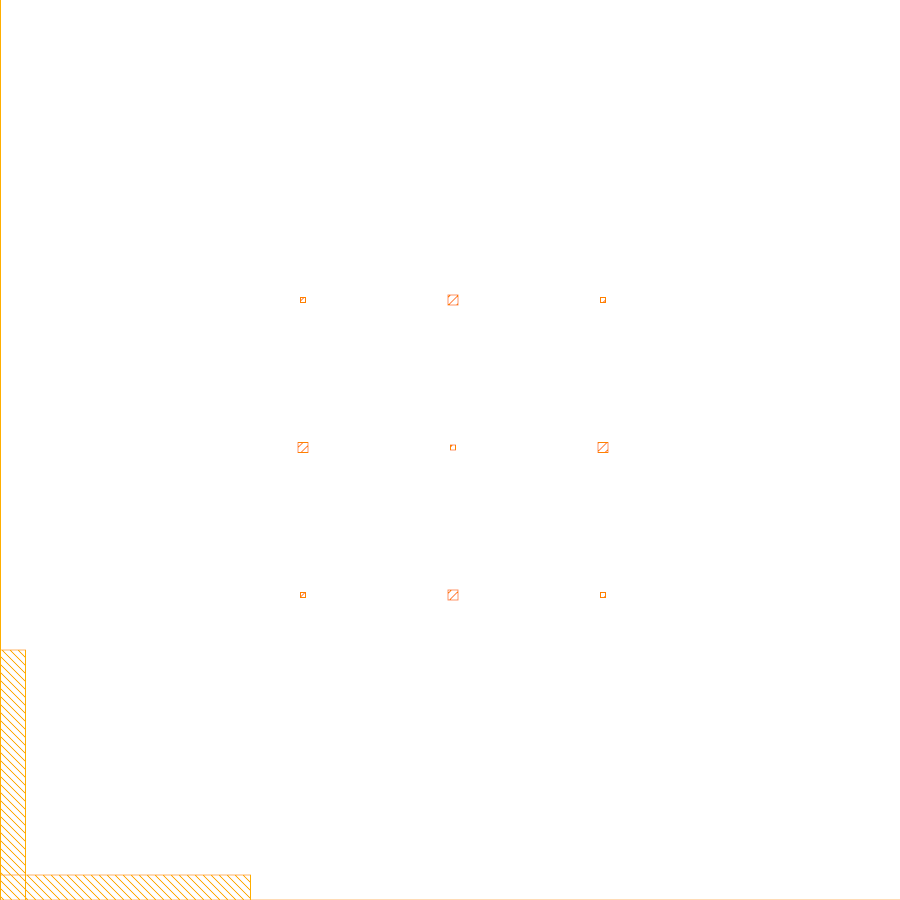

In [17]:
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
TX, TY = d.data["instances"]["clt1"]["place"]["at"]
show_snapshot(d, OUT / "a3_four_qubit_mux.png", size=(1800, 1100))
show_snapshot(d, OUT / "a3_four_qubit_mux_q1.png", box=(QX - 450, QY - 450, QX + 450, QY + 450), width=420)
show_snapshot(d, OUT / "a3_four_qubit_mux_jj.png", box=(QX - 40, QY - 40, QX + 40, QY + 40), width=300)
show_snapshot(d, OUT / "a3_four_qubit_mux_tee.png", box=(TX - 300, TY - 400, TX + 300, TY + 200), width=360)
snap_file(Path("build") / "a3_four_qubit_mux_fab.oas", OUT / "a3_four_qubit_mux_cheese.png",
          box=(QX - 650, QY - 650, QX + 650, QY + 650), size=(1300, 1300), width=420)
show_snapshot(d, OUT / "a3_four_qubit_mux_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, their relative positions, the five feedline segments, the route end pins, the readout lengths (6.8 / 7.0 / 7.2 / 7.4 mm), the sim groups |
| PDK changes | QCT frame on the source's 16 × 9 mm box; sapphire stack; launchpads 100 µm from the west / east edges (were 240 µm); trilayer junctions (PDK nominal); PDK cheese band; content centred (shift printed in step 7) |
| differs | the meanders' shapes (qcc router); f_q ≈ 7.4 GHz with the PDK junction (the 10 nH Metal default gave 6.75 GHz) |
| PDK design warnings | none |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |